In [29]:

import pandas as pd

# A/B test dataset
data = {
    "customer_id": [1, 2, 3, 4, 5, 6],
    "group": ["A", "A", "A", "B", "B", "B"],
    "purchased": [0, 1, 0, 1, 1, 0]
}

df = pd.DataFrame(data)

print(df)

conversion_rates = df.groupby("group")["purchased"].mean()

print(conversion_rates * 100)


   customer_id group  purchased
0            1     A          0
1            2     A          1
2            3     A          0
3            4     B          1
4            5     B          1
5            6     B          0
group
A    33.333333
B    66.666667
Name: purchased, dtype: float64


In [30]:

import pandas as pd

# Loading the public Hillstrom marketing dataset
url = "https://hillstorm1.s3.us-east-2.amazonaws.com/hillstorm_no_indices.csv.gz"

df = pd.read_csv(url, compression="gzip")

# Displaying the first 5 customers
print(df.head())


   recency history_segment  history  mens  womens   zip_code  newbie channel  \
0       10  2) $100 - $200   142.44     1       0  Surburban       0   Phone   
1        6  3) $200 - $350   329.08     1       1      Rural       1     Web   
2        7  2) $100 - $200   180.65     0       1  Surburban       1     Web   
3        9  5) $500 - $750   675.83     1       0      Rural       1     Web   
4        2    1) $0 - $100    45.34     1       0      Urban       0     Web   

         segment  visit  conversion  spend  
0  Womens E-Mail      0           0    0.0  
1      No E-Mail      0           0    0.0  
2  Womens E-Mail      0           0    0.0  
3    Mens E-Mail      0           0    0.0  
4  Womens E-Mail      0           0    0.0  


In [31]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())


Number of rows: 64000
Number of columns: 12

Column names:
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


In [32]:

# Makeing the column names lowercase for consistency
df.columns = df.columns.str.lower()

# Counting the customers assigned to each email group
print(df["segment"].value_counts())


segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


In [33]:

# Calculate purchase conversion rate for each group
conversion_rates = (
    df.groupby("segment")["conversion"]
    .agg(["count", "sum", "mean"])
)

# Converted mean into a percentage
conversion_rates["conversion_rate_%"] = (
    conversion_rates["mean"] * 100
)

print(conversion_rates.round(2))


               count  sum  mean  conversion_rate_%
segment                                           
Mens E-Mail    21307  267  0.01               1.25
No E-Mail      21306  122  0.01               0.57
Womens E-Mail  21387  189  0.01               0.88


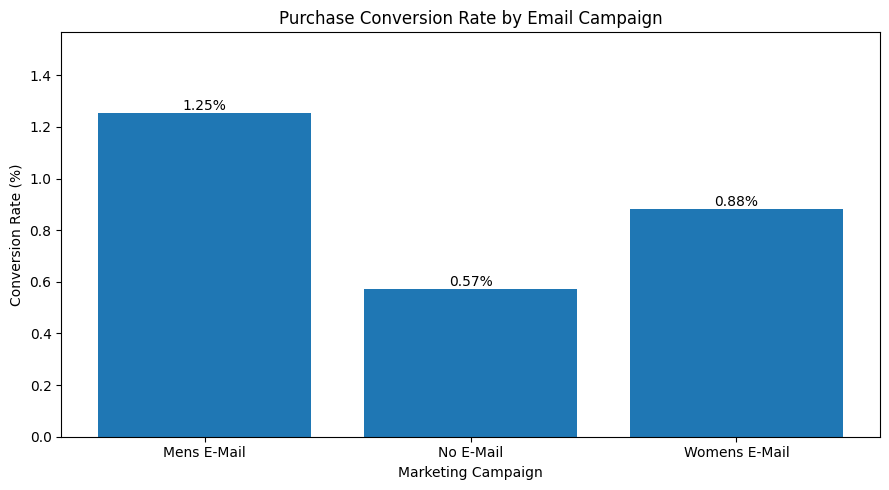

In [34]:

import matplotlib.pyplot as plt

rates = conversion_rates["conversion_rate_%"]

plt.figure(figsize=(9, 5))
bars = plt.bar(rates.index, rates.values)

plt.title("Purchase Conversion Rate by Email Campaign")
plt.xlabel("Marketing Campaign")
plt.ylabel("Conversion Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.ylim(0, rates.max() * 1.25)
plt.tight_layout()
plt.show()


In [35]:

from statsmodels.stats.proportion import proportions_ztest

# Men's Email group
men = df[df["segment"] == "Mens E-Mail"]

# No Email group
control = df[df["segment"] == "No E-Mail"]

# Number of customers who purchased
purchases = [
    men["conversion"].sum(),
    control["conversion"].sum()
]

# Total customers in each group
customers = [
    len(men),
    len(control)
]

# Two-proportion Z-test
z_stat, p_value = proportions_ztest(
    count=purchases,
    nobs=customers,
    alternative="two-sided"
)

print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("No statistically significant difference detected")


Z-statistic: 7.3851
P-value: 1.5232235005955427e-13
Statistically significant difference


In [36]:

# Calculate actual conversion rates
men_rate = men["conversion"].mean()
control_rate = control["conversion"].mean()

# Absolute improvement
absolute_lift = men_rate - control_rate

# Relative improvement
relative_lift = (absolute_lift / control_rate) * 100

# Estimate incremental conversions
extra_purchases = absolute_lift * len(men)

print("Men's Email conversion:", round(men_rate * 100, 3), "%")
print("No Email conversion:", round(control_rate * 100, 3), "%")
print("Absolute lift:", round(absolute_lift * 100, 3),
      "percentage points")
print("Relative lift:", round(relative_lift, 2), "%")
print("Estimated extra purchases:", round(extra_purchases))


Men's Email conversion: 1.253 %
No Email conversion: 0.573 %
Absolute lift: 0.681 percentage points
Relative lift: 118.84 %
Estimated extra purchases: 145


In [37]:

import numpy as np
from statsmodels.stats.proportion import confint_proportions_2indep

# we Calculated 95% confidence interval for the difference
ci_low, ci_high = confint_proportions_2indep(
    count1=int(men["conversion"].sum()),
    nobs1=len(men),
    count2=int(control["conversion"].sum()),
    nobs2=len(control),
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("Estimated lift:",
      round(absolute_lift * 100, 3),
      "percentage points")

print("95% confidence interval:",
      round(ci_low * 100, 3),
      "to",
      round(ci_high * 100, 3),
      "percentage points")


Estimated lift: 0.681 percentage points
95% confidence interval: 0.501 to 0.864 percentage points


In [38]:

# Analyzed revenue performance across all groups
revenue_analysis = df.groupby("segment").agg(
    customers=("spend", "count"),
    total_revenue=("spend", "sum"),
    avg_revenue_per_customer=("spend", "mean"),
    purchasers=("conversion", "sum")
)

print(revenue_analysis.round(2))


               customers  total_revenue  avg_revenue_per_customer  purchasers
segment                                                                      
Mens E-Mail        21307       30311.69                      1.42         267
No E-Mail          21306       13908.33                      0.65         122
Womens E-Mail      21387       23038.11                      1.08         189


In [39]:

# Average revenue for Men's Email customers
men_revenue = men["spend"].mean()

# Average revenue for control customers
control_revenue = control["spend"].mean()

# Additional revenue per customer
revenue_lift = men_revenue - control_revenue

# Estimated incremental revenue for Men's Email group
incremental_revenue = revenue_lift * len(men)

print("Men's Email revenue/customer: $",
      round(men_revenue, 2))

print("No Email revenue/customer: $",
      round(control_revenue, 2))

print("Incremental revenue/customer: $",
      round(revenue_lift, 2))

print("Estimated incremental revenue: $",
      round(incremental_revenue, 2))


Men's Email revenue/customer: $ 1.42
No Email revenue/customer: $ 0.65
Incremental revenue/customer: $ 0.77
Estimated incremental revenue: $ 16402.71


In [40]:

import numpy as np

# Revenue values from both groups
men_spend = men["spend"].to_numpy()
control_spend = control["spend"].to_numpy()

# Random number generator for reproducibility
rng = np.random.default_rng(42)

# Store the results of 2000 bootstrap samples
bootstrap_lifts = []

for i in range(2000):
    men_sample = rng.choice(
        men_spend, size=len(men_spend), replace=True
    )

    control_sample = rng.choice(
        control_spend, size=len(control_spend), replace=True
    )

    lift = men_sample.mean() - control_sample.mean()
    bootstrap_lifts.append(lift)

# Calculate the 95% bootstrap confidence interval
lower, upper = np.percentile(
    bootstrap_lifts, [2.5, 97.5]
)

print("Revenue lift per customer: $",
      round(revenue_lift, 3))

print("95% Bootstrap CI: $",
      round(lower, 3), "to $", round(upper, 3))

if lower > 0:
    print("Revenue lift is statistically significant "
          "under this bootstrap analysis.")
else:
    print("The interval includes zero or negative values; "
          "revenue improvement is uncertain.")

Revenue lift per customer: $ 0.77
95% Bootstrap CI: $ 0.484 to $ 1.052
Revenue lift is statistically significant under this bootstrap analysis.


In [41]:

# Compare conversion and revenue across all groups

campaign_summary = df.groupby("segment").agg(
    customers=("conversion", "count"),
    purchases=("conversion", "sum"),
    conversion_rate=("conversion", "mean"),
    total_revenue=("spend", "sum"),
    revenue_per_customer=("spend", "mean")
)

campaign_summary["conversion_rate"] *= 100

print(campaign_summary.round(3).to_string())


               customers  purchases  conversion_rate  total_revenue  revenue_per_customer
segment                                                                                  
Mens E-Mail        21307        267            1.253       30311.69                 1.423
No E-Mail          21306        122            0.573       13908.33                 0.653
Womens E-Mail      21387        189            0.884       23038.11                 1.077


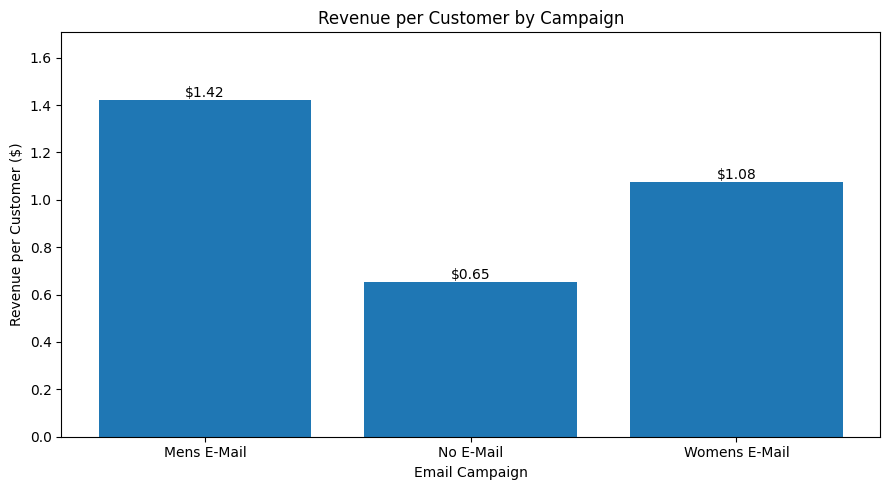

In [42]:

import matplotlib.pyplot as plt

revenue = campaign_summary["revenue_per_customer"]

plt.figure(figsize=(9, 5))

bars = plt.bar(revenue.index, revenue.values)

plt.title("Revenue per Customer by Campaign")
plt.xlabel("Email Campaign")
plt.ylabel("Revenue per Customer ($)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"${bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, revenue.max() * 1.2)
plt.tight_layout()
plt.savefig("revenue_comparison.png", dpi=300)
plt.show()
